# 03 — Frequentist analysis of $\log A$

**What this notebook does**

- describes the distribution of $\log A$ in the 4 experimental groups (2 cell lines × 2 regions) and checks the Gaussian hypothesis;
- estimates the parameters with an unbinned **maximum-likelihood** fit (`iminuit`), with Hesse and Minos errors;
- compares nucleus and cytoplasm (for each line) with the **profile likelihood** of $\Delta=\mu_{nucleus}-\mu_{cytoplasm}$ and the likelihood-ratio (Wilks) test, next to Welch, Mann–Whitney, permutation and bootstrap;
- checks the behaviour of the method with **toy MC**: bias, pulls, interval coverage, size and power of the tests at the real number of curves;
- tests the line × region interaction with nested models;
- quantifies the preprocessing **systematics** (9 variants, Barlow criterion);
- applies the multiple-testing correction (Holm).

**What it does NOT do**

- it does not redo the curve fits (notebook 02): it only reads `results/`;
- it does not convert $A$ into a Young modulus;
- it does not treat curves as independent cells *by construction*: curves of the same cell are correlated and the cell identifier is not available (see «Limits» below). The errors are therefore optimistic;
- the comparison **between lines** (MCF7R vs T47DR) is confounded with the experimental session (different dates: 25/02 and 18/03): it is reported but cannot be read as a biological effect.

Notation: $x_i=\log A_i$ (with $A$ in nN/µm$^{3/2}$), group $g$ with $n_g$ curves, model $x\sim\mathcal N(\mu_g,\sigma_g^2)$. Region labels follow the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize
from iminuit import Minuit
import afm_tools as T

T.set_plot_style()
RNG = np.random.default_rng(20261016)
fit = T.load_fit_table()
ana = T.good_sample(fit)                 # curves with a 'good' fit
print(len(fit), "curves in total;", len(ana), "used")
groups = [g for g in T.GROUP_ORDER if g in set(ana.group)]
X = {g: ana.loc[ana.group == g, "logA"].to_numpy() for g in groups}
lines = ["MCF7R", "T47DR"]
G = {(l, r): ana[(ana.cell_line == l) & (ana.region == r)].group.iloc[0] for l in lines for r in ["cito", "nucleo"]}
summary = {}
pd.DataFrame({T.short_group(g): pd.Series(x).describe() for g, x in X.items()}).T.round(3)

257 curves in total; 257 used


,count,mean,std,min,25%,50%,75%,max
MCF7R cito,55.0,0.057,0.477,-1.050,-0.245,0.072,0.475,1.084
MCF7R nucleo,60.0,-0.757,0.327,-1.350,-1.002,-0.798,-0.550,0.043
T47DR cito,59.0,-0.101,0.508,-1.106,-0.527,-0.146,0.296,0.987
T47DR nucleo,83.0,-0.348,0.637,-1.448,-0.830,-0.414,-0.016,1.632


## 1. Distributions and Gaussian-shape check

$A$ is positive and skewed; $\log A$ should be more symmetric. We check it with histograms and Shapiro–Wilk. Since the Gaussian model on $\log A$ (i.e. *log-normal* for $A$) is an assumption, we will also check it with non-parametric tests.

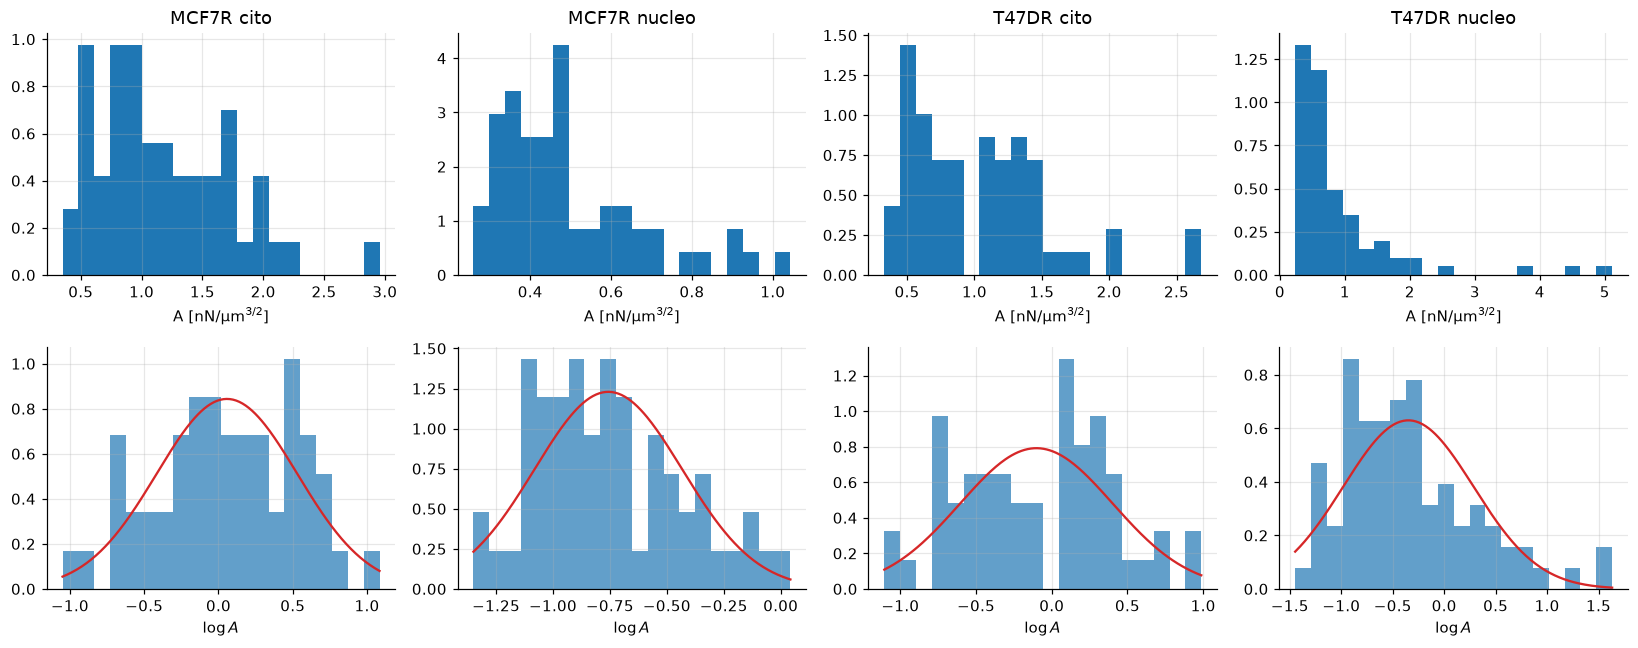

,group,n,mean,sd,skew_A,skew_logA,shapiro_p
0,MCF7R cito,55,0.057,0.473,0.785,-0.206,0.704
1,MCF7R nucleo,60,-0.757,0.325,1.213,0.538,0.089
2,T47DR cito,59,-0.101,0.504,1.090,0.027,0.202
3,T47DR nucleo,83,-0.348,0.633,3.105,0.942,0.001


In [2]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
rows = []
for k, g in enumerate(groups):
    x = X[g]; mu, sd = x.mean(), x.std()
    a = axs[0, k]; a.hist(np.exp(x), bins=20, density=True); a.set_title(T.short_group(g)); a.set_xlabel("A [nN/µm$^{3/2}$]")
    b = axs[1, k]; b.hist(x, bins=20, density=True, alpha=.7); t = np.linspace(x.min(), x.max(), 200)
    b.plot(t, stats.norm.pdf(t, mu, sd), "C3"); b.set_xlabel(r"$\log A$")
    rows.append(dict(group=T.short_group(g), n=len(x), mean=mu, sd=sd, skew_A=stats.skew(np.exp(x)),
                     skew_logA=stats.skew(x), shapiro_p=stats.shapiro(x).pvalue))
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

## 2. Maximum-likelihood fit per group

Unbinned likelihood $\mathcal L=\prod_g\prod_{i\in g}\mathcal N(x_i;\mu_g,\sigma_g)$. The minimizer is `iminuit`; we compare the Hesse errors with the analytic formula $\sigma/\sqrt{n}$.

In [3]:
def nll_group(x):
    def f(mu, sigma):
        return 0.5 * np.sum(((x - mu) / sigma) ** 2) + len(x) * np.log(sigma)
    return f

rows = []
for g in groups:
    m = Minuit(nll_group(X[g]), mu=X[g].mean(), sigma=X[g].std()); m.errordef = Minuit.LIKELIHOOD
    m.limits["sigma"] = (1e-3, None); m.migrad(); m.hesse(); m.minos("mu")
    rows.append(dict(group=T.short_group(g), n=len(X[g]), mu=m.values["mu"], err_hesse=m.errors["mu"],
                     minos_lo=m.merrors["mu"].lower, minos_hi=m.merrors["mu"].upper, sigma=m.values["sigma"],
                     err_sigma=m.errors["sigma"], err_analytic=X[g].std() / np.sqrt(len(X[g])), valid=m.valid))
mle = pd.DataFrame(rows); summary["mle_per_group"] = mle.round(4).to_dict("records"); mle.round(4)

,group,n,mu,err_hesse,minos_lo,minos_hi,sigma,err_sigma,err_analytic,valid
0,MCF7R cito,55,0.0569,0.0638,-0.0641,0.0641,0.4729,0.0451,0.0638,True
1,MCF7R nucleo,60,-0.7570,0.0419,-0.0421,0.0421,0.3245,0.0296,0.0419,True
2,T47DR cito,59,-0.1014,0.0656,-0.0659,0.0659,0.5039,0.0464,0.0656,True
3,T47DR nucleo,83,-0.3482,0.0695,-0.0697,0.0697,0.6334,0.0491,0.0695,True


## 3. Nucleus versus cytoplasm: profile likelihood

For each line we reparametrize $(\mu_{cito},\Delta,\sigma_{cito},\sigma_{nucleo})$ with $\mu_{nucleo}=\mu_{cito}+\Delta$. The **profile** $-2\Delta\ln\mathcal L(\Delta)$ minimizes over the nuisance parameters; the 68% interval is where it rises by 1 (Wilks). The test of $H_0:\Delta=0$ uses $q=-2\ln[\mathcal L(\hat{\hat\theta}|\Delta=0)/\mathcal L(\hat\theta)]\sim\chi^2_1$.

Since for fixed $\Delta$ the minimization over $\sigma_{cito},\sigma_{nucleo}$ is analytic, the profile reduces to a one-dimensional problem in $\mu_{cito}$, used both here and in the toy MC.

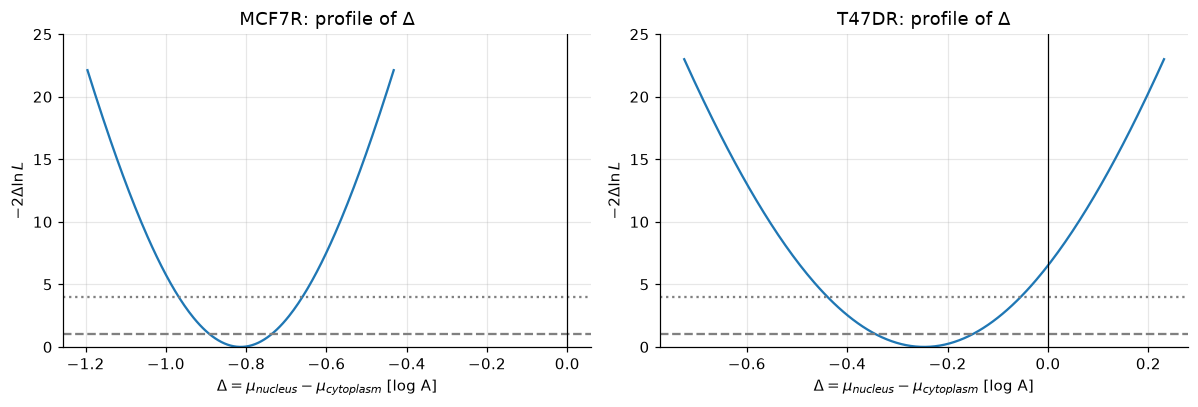

,delta,lo68,hi68,q0,p,z
MCF7R,-0.8139,-0.8904,-0.7374,70.7437,0.0000,-8.4109
T47DR,-0.2468,-0.3425,-0.1510,6.5115,0.0107,-2.5518


In [4]:
def prof_m2lnL(delta, xc, xn):
    # -2 ln L profiled over (mu_c, sigma_c, sigma_n) at fixed Delta (constants dropped)
    nc, nn = len(xc), len(xn)
    def f(mu):
        return nc * np.log(np.mean((xc - mu) ** 2)) + nn * np.log(np.mean((xn - mu - delta) ** 2))
    lo, hi = min(xc.min(), (xn - delta).min()), max(xc.max(), (xn - delta).max())
    return optimize.minimize_scalar(f, bounds=(lo, hi), method="bounded", options={"xatol": 1e-9}).fun

def delta_fit(xc, xn):
    d_hat = xn.mean() - xc.mean()
    p0 = prof_m2lnL(d_hat, xc, xn)
    f = lambda d: prof_m2lnL(d, xc, xn) - p0
    s = np.hypot(xc.std() / np.sqrt(len(xc)), xn.std() / np.sqrt(len(xn)))
    lo1 = optimize.brentq(lambda d: f(d) - 1, d_hat - 8 * s, d_hat)
    hi1 = optimize.brentq(lambda d: f(d) - 1, d_hat, d_hat + 8 * s)
    q0 = f(0.0)
    return dict(delta=d_hat, lo68=lo1, hi68=hi1, q0=q0, p=stats.chi2.sf(q0, 1), z=np.sign(d_hat) * np.sqrt(q0), f=f, s=s)

res_delta = {l: delta_fit(X[G[l, "cito"]], X[G[l, "nucleo"]]) for l in lines}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, l in zip(ax, lines):
    r = res_delta[l]; d = np.linspace(r["delta"] - 5 * r["s"], r["delta"] + 5 * r["s"], 200)
    a.plot(d, [r["f"](v) for v in d]); a.axhline(1, ls="--", c="gray"); a.axhline(4, ls=":", c="gray")
    a.axvline(0, c="k", lw=.8); a.set_ylim(0, 25); a.set_title(f"{l}: profile of $\\Delta$"); a.set_xlabel(r"$\Delta=\mu_{nucleus}-\mu_{cytoplasm}$ [log A]")
    a.set_ylabel(r"$-2\Delta\ln L$")
plt.tight_layout(); plt.show()
pd.DataFrame({l: {k: v for k, v in r.items() if k not in ("f", "s")} for l, r in res_delta.items()}).T.round(4)

### Comparison with other tests on the same sample

Welch ($t$ with unequal variances), Mann–Whitney (non-parametric), permutation test on the difference of means and bootstrap on the difference of **medians** (robust to non-Gaussian tails). If the methods agree, the conclusion does not depend on the Gaussian assumption.

In [5]:
def perm_test(xc, xn, n=20000):
    obs = xn.mean() - xc.mean(); pool = np.concatenate([xc, xn]); cnt = 0
    for _ in range(n):
        RNG.shuffle(pool); cnt += abs(pool[len(xc):].mean() - pool[:len(xc)].mean()) >= abs(obs)
    return (cnt + 1) / (n + 1)

rows = []
for l in lines:
    xc, xn = X[G[l, "cito"]], X[G[l, "nucleo"]]; r = res_delta[l]
    bm = T.bootstrap_stat(xn, np.median, 10000, 1) - T.bootstrap_stat(xc, np.median, 10000, 2)
    rows.append(dict(line=l, delta_mean=r["delta"], p_wilks=r["p"], p_welch=stats.ttest_ind(xn, xc, equal_var=False).pvalue,
                     p_mannwhitney=stats.mannwhitneyu(xn, xc).pvalue, p_perm=perm_test(xc, xn),
                     delta_median=np.median(xn) - np.median(xc), boot_med_lo95=np.quantile(bm, .025), boot_med_hi95=np.quantile(bm, .975),
                     cohen_d=(xn.mean() - xc.mean()) / np.sqrt((xn.var(ddof=1) + xc.var(ddof=1)) / 2),
                     A_ratio=np.exp(r["delta"])))
cmp = pd.DataFrame(rows).set_index("line"); summary["nucleus_vs_cito"] = cmp.round(5).to_dict("index")
cmp.round(5)

,delta_mean,p_wilks,p_welch,p_mannwhitney,p_perm,delta_median,boot_med_lo95,boot_med_hi95,cohen_d,A_ratio
line,,,,,,,,,,
MCF7R,-0.81390,0.00000,0.00000,0.00000,0.00005,-0.86907,-1.08391,-0.66016,-1.98893,0.44312
T47DR,-0.24678,0.01072,0.01144,0.00338,0.01540,-0.26818,-0.66502,-0.07161,-0.42818,0.78131


$\exp\Delta$ is the nucleus/cytoplasm ratio of the typical values of $A$ (median, since $A$ is log-normal): values $<1$ mean a *softer nucleus* than the cytoplasm according to the effective parameter.

## 4. Validation with toy MC

The profile likelihood is exact only asymptotically; with $n\approx 55$–$83$ per group we check:

1. **bias and pull** of $\hat\Delta$ (generating from $\mathcal N(\hat\mu_g,\hat\sigma_g)$ with the fitted values);
2. **coverage** of the 68% profile interval;
3. **size** (rejection fraction under $H_0$ at 5%) and **power** of the Wilks test, compared with Welch and Mann–Whitney.

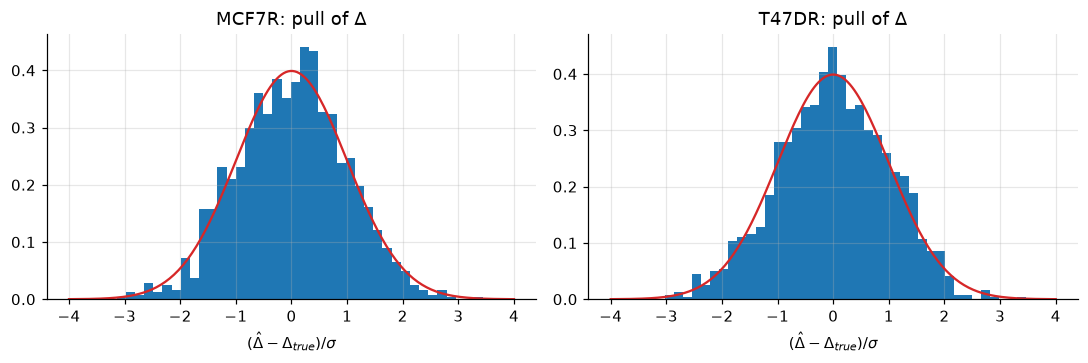

,delta_true,bias,pull_mean,pull_std,coverage_68,size_wilks,size_welch,size_mw,power_wilks,power_welch,power_mw
line,,,,,,,,,,,
MCF7R,-0.814,0.001,0.007,0.976,0.680,0.059,0.058,0.055,1.000,1.000,1.000
T47DR,-0.247,0.001,0.006,0.996,0.679,0.052,0.051,0.043,0.727,0.721,0.688


In [6]:
def toys(l, n_toy=1500, shift=None, seed=0):
    rg = np.random.default_rng(seed)
    gc, gn = G[l, "cito"], G[l, "nucleo"]; xc0, xn0 = X[gc], X[gn]
    mc, sc, mn, sn = xc0.mean(), xc0.std(), xn0.mean(), xn0.std()
    d_true = (mn - mc) if shift is None else shift
    out = []
    for _ in range(n_toy):
        xc = rg.normal(mc, sc, len(xc0)); xn = rg.normal(mc + d_true, sn, len(xn0))
        r = delta_fit(xc, xn)
        out.append((r["delta"], (r["hi68"] - r["lo68"]) / 2, r["lo68"] <= d_true <= r["hi68"], r["p"],
                    stats.ttest_ind(xn, xc, equal_var=False).pvalue, stats.mannwhitneyu(xn, xc).pvalue))
    a = np.array(out); return d_true, a

rows, pulls = [], {}
for l in lines:
    d_true, a = toys(l, seed=1)
    pull = (a[:, 0] - d_true) / a[:, 1]; pulls[l] = pull
    _, h0 = toys(l, shift=0.0, seed=2)
    rows.append(dict(line=l, delta_true=d_true, bias=a[:, 0].mean() - d_true, pull_mean=pull.mean(), pull_std=pull.std(),
                     coverage_68=a[:, 2].mean(), size_wilks=(h0[:, 3] < .05).mean(), size_welch=(h0[:, 4] < .05).mean(),
                     size_mw=(h0[:, 5] < .05).mean(), power_wilks=(a[:, 3] < .05).mean(),
                     power_welch=(a[:, 4] < .05).mean(), power_mw=(a[:, 5] < .05).mean()))
toy_tab = pd.DataFrame(rows).set_index("line"); summary["toys"] = toy_tab.round(4).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a_, l in zip(ax, lines):
    a_.hist(pulls[l], bins=40, density=True); t = np.linspace(-4, 4, 200); a_.plot(t, stats.norm.pdf(t), "C3")
    a_.set_title(f"{l}: pull of $\\Delta$"); a_.set_xlabel(r"$(\hat\Delta-\Delta_{true})/\sigma$")
plt.tight_layout(); plt.show()
toy_tab.round(3)

**Power at small effects.** What is the smallest $|\Delta|$ detectable with $n$ curves per group? Power curve of the Wilks test for the numbers of curves of MCF7R and T47DR.

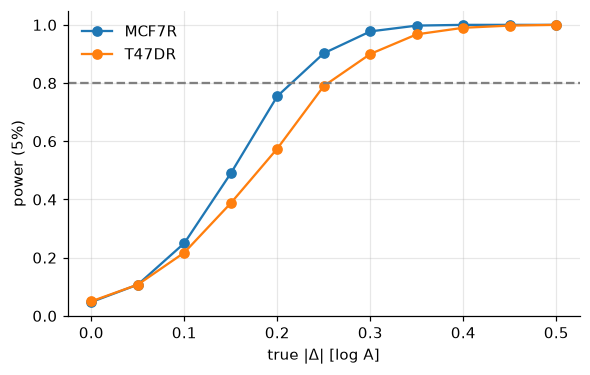

{'MCF7R': 0.2152542372881356, 'T47DR': 0.2545454545454546}

In [7]:
shifts = np.linspace(0, 0.5, 11); pw = {}
for l in lines:
    pw[l] = [(toys(l, n_toy=400, shift=s, seed=3)[1][:, 3] < .05).mean() for s in shifts]
fig, ax = plt.subplots(figsize=(6, 3.6))
for l in lines: ax.plot(shifts, pw[l], "o-", label=l)
ax.axhline(.8, ls="--", c="gray"); ax.set_xlabel(r"true $|\Delta|$ [log A]"); ax.set_ylabel("power (5%)"); ax.legend(); plt.show()
summary["power_80pct_delta"] = {l: float(np.interp(.8, pw[l], shifts)) for l in lines}; summary["power_80pct_delta"]

## 5. All groups: line × region interaction and comparison between lines

Full model (4 means, 4 sigmas) against the **additive** model $\mu_{l,r}=a_l+b_r$ (3 mean parameters): the nested test ($\chi^2_1$) tells whether the nucleus–cytoplasm effect depends on the line. The comparison between lines at equal region is reported with the caveat on the session (different dates).

In [8]:
names = [(l, r) for l in lines for r in ["cito", "nucleo"]]
xs = [X[G[k]] for k in names]
def m2lnl(mus):
    return sum(len(x) * np.log(np.mean((x - m) ** 2)) for x, m in zip(xs, mus))
full = m2lnl([x.mean() for x in xs])
def additive(p):
    a_M, a_T, b = p     # b = nucleus effect
    return m2lnl([a_M, a_M + b, a_T, a_T + b])
opt = optimize.minimize(additive, [xs[0].mean(), xs[2].mean(), -0.5], method="Nelder-Mead", options={"xatol": 1e-9, "fatol": 1e-9})
q_int = opt.fun - full
print(f"line x region interaction: q = {q_int:.2f}, p = {stats.chi2.sf(q_int, 1):.3g}  (common nucleus effect b = {opt.x[2]:.3f})")
summary["interaction"] = dict(q=float(q_int), p=float(stats.chi2.sf(q_int, 1)), b_common=float(opt.x[2]))

rows = []
for r in ["cito", "nucleo"]:
    xa, xb = X[G["MCF7R", r]], X[G["T47DR", r]]; d = xb.mean() - xa.mean()
    rows.append(dict(region=r, delta_T47DR_minus_MCF7R=d, err=np.hypot(xa.std() / np.sqrt(len(xa)), xb.std() / np.sqrt(len(xb))),
                     p_welch=stats.ttest_ind(xb, xa, equal_var=False).pvalue, p_mw=stats.mannwhitneyu(xb, xa).pvalue))
lines_tab = pd.DataFrame(rows).set_index("region"); summary["line_vs_line"] = lines_tab.round(5).to_dict("index"); lines_tab.round(4)

line x region interaction: q = 20.57, p = 5.74e-06  (common nucleus effect b = -0.594)


,delta_T47DR_minus_MCF7R,err,p_welch,p_mw
region,,,,
cito,-0.1583,0.0915,0.0891,0.0817
nucleo,0.4088,0.0812,0.0000,0.0000


## 6. Multiple-testing correction (Holm)

The 4 confirmatory questions — nucleus vs cytoplasm in MCF7R and T47DR, MCF7R vs T47DR in cytoplasm and in nucleus — are corrected with Holm–Bonferroni (p from the Wilks / Welch test).

In [9]:
tests = {"nucleus-cito MCF7R": res_delta["MCF7R"]["p"], "nucleus-cito T47DR": res_delta["T47DR"]["p"],
         "T47DR-MCF7R cito": lines_tab.loc["cito", "p_welch"], "T47DR-MCF7R nucleo": lines_tab.loc["nucleo", "p_welch"]}
order = sorted(tests, key=tests.get); m_ = len(order); holm = {}; run = 0
for i, k in enumerate(order):
    run = max(run, min(1, (m_ - i) * tests[k])); holm[k] = run
holm_tab = pd.DataFrame({"p": tests, "p_Holm": holm}); summary["holm"] = holm_tab.to_dict("index"); holm_tab

,p,p_Holm
nucleus-cito MCF7R,4.067886e-17,1.627155e-16
nucleus-cito T47DR,1.071765e-02,2.143529e-02
T47DR-MCF7R cito,8.911882e-02,8.911882e-02
T47DR-MCF7R nucleo,1.807630e-06,5.422891e-06


## 7. Preprocessing systematics

We repeat the estimate of $\Delta$ (nucleus – cytoplasm, per line) with the 9 variants of notebook 02. Barlow criterion: the shift $\delta_{var}=\Delta_{var}-\Delta_{nom}$ is significant if $|\delta_{var}|/\sqrt{|\sigma_{var}^2-\sigma_{nom}^2|}>2$; the variants are computed on the *same curves*, so $\sigma_{var}^2-\sigma_{nom}^2$ is the uncorrelated part of the statistical error. As total systematic uncertainty we take the quadrature sum of the significant shifts.

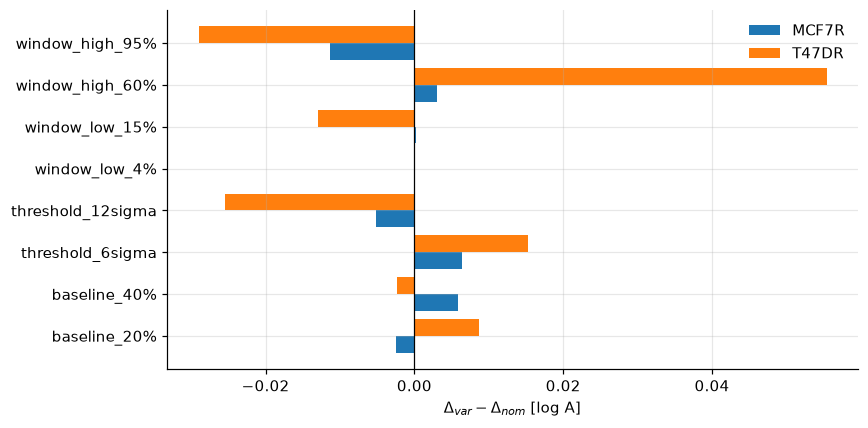

total systematic (significant shifts, in quadrature): {'MCF7R': 0.0, 'T47DR': 0.0675}
statistical error: {'MCF7R': 0.0765, 'T47DR': 0.0958}


,line,variant,delta,shift,barlow,err_stat,significant
0,MCF7R,baseline_20%,-0.8164,-0.0025,0.4456,0.0765,False
1,MCF7R,baseline_40%,-0.8080,0.0059,0.6107,0.0765,False
2,MCF7R,threshold_6sigma,-0.8075,0.0064,0.5494,0.0765,False
3,MCF7R,threshold_12sigma,-0.8191,-0.0052,0.3608,0.0765,False
4,MCF7R,window_low_4%,-0.8139,0.0000,NaN,0.0765,False
5,MCF7R,window_low_15%,-0.8137,0.0002,0.0322,0.0765,False
6,MCF7R,window_high_60%,-0.8109,0.0030,0.0964,0.0765,False
7,MCF7R,window_high_95%,-0.8252,-0.0113,0.6322,0.0765,False
8,T47DR,baseline_20%,-0.2381,0.0087,1.3509,0.0958,False
9,T47DR,baseline_40%,-0.2491,-0.0023,0.1937,0.0958,False


In [10]:
var = pd.read_csv(T.RESULTS_DIR / "fit_variants.csv")
def delta_variant(v, l):
    sub = var[(var.variant == v) & var.fit_quality_flag.isin(["good"]) & np.isfinite(var.logA)]
    xc = sub[sub.group == G[l, "cito"]].logA.to_numpy(); xn = sub[sub.group == G[l, "nucleo"]].logA.to_numpy()
    r = delta_fit(xc, xn); return r["delta"], (r["hi68"] - r["lo68"]) / 2
rows = []
for l in lines:
    d0, s0 = delta_variant("nominal", l)
    for v in var.variant.unique():
        if v == "nominal": continue
        d, s = delta_variant(v, l); sh = d - d0; den = np.sqrt(abs(s ** 2 - s0 ** 2))
        rows.append(dict(line=l, variant=v, delta=d, shift=sh, barlow=abs(sh) / den if den > 1e-9 else np.nan, err_stat=s0))
syst = pd.DataFrame(rows)
syst["significant"] = syst.barlow > 2
tot = {l: float(np.sqrt((syst[(syst.line == l) & syst.significant]["shift"] ** 2).sum())) for l in lines}
summary["systematics"] = dict(total_in_quadrature=tot, stat={l: float((res_delta[l]['hi68'] - res_delta[l]['lo68']) / 2) for l in lines})
fig, ax = plt.subplots(figsize=(8, 4))
for i, l in enumerate(lines):
    s = syst[syst.line == l]; ax.barh(np.arange(len(s)) + .4 * i, s["shift"], .4, label=l)
ax.set_yticks(np.arange(len(s)) + .2, s.variant); ax.axvline(0, c="k", lw=.8); ax.legend()
ax.set_xlabel(r"$\Delta_{var}-\Delta_{nom}$ [log A]"); plt.tight_layout(); plt.show()
print("total systematic (significant shifts, in quadrature):", {k: round(v, 4) for k, v in tot.items()})
print("statistical error:", {k: round(v, 4) for k, v in summary['systematics']['stat'].items()})
syst.round(4)

## 8. Fit error versus spread between curves

If the uncertainty of the single fit ($\sigma_A/A$ from `curve_fit`) were comparable to the spread of $\log A$ between curves, the observed variability would be mostly measurement noise; if it is much smaller, the spread is intrinsic (different cells, different points of the same cell).

In [11]:
rel = (ana.A_err_nN_per_um_3over2 / ana.A_nN_per_um_3over2)
print(f"median relative fit error: {rel.median():.3f}   spread of logA between curves (sd, median over groups): {np.median([x.std() for x in X.values()]):.3f}")
summary["fit_err_rel_median"] = float(rel.median())

median relative fit error: 0.008   spread of logA between curves (sd, median over groups): 0.488


In [12]:
json.dump(summary, open(T.RESULTS_DIR / "03_summary.json", "w"), indent=1, default=float)
(res := pd.DataFrame({l: dict(delta=r["delta"], lo68=r["lo68"], hi68=r["hi68"], p_wilks=r["p"]) for l, r in res_delta.items()}).T).round(4)

,delta,lo68,hi68,p_wilks
MCF7R,-0.8139,-0.8904,-0.7374,0.0000
T47DR,-0.2468,-0.3425,-0.1510,0.0107


## Limits and interpretation

- **Pseudo-replication.** Curves are not independent cells: several curves come from the same cell and from the same cantilever/session. Without the cell identifier the statistical errors are underestimated; a hierarchical model (cell within group) is the natural next step, discussed in notebook 04.
- **Cell line ≡ session.** MCF7R (25/02) and T47DR (18/03) were measured on different days: the difference between lines cannot be separated from session effects (calibration, cantilever, state of the cells). The nucleus–cytoplasm effect *within* a line can, because the two regions are measured in the same session.
- **Effective parameter.** $A$ depends on the tip geometry (unknown from the metadata) and on the Hertz assumption with exponent 3/2; comparisons are valid only in relative terms.
- **Pre-selected curves.** The data are the «good curves» already chosen upstream: all pass the `good` QC; there is no sample of real defective curves on which to estimate the selection efficiency.

## Output produced and next step

```text
results/03_summary.json     MLE per group, nucleus–cytoplasm Δ (profile), tests, toy MC, interaction, Holm, systematics
```

Next: `04_bayesian_analysis.ipynb` — the same model in a Bayesian setting, with a hierarchical structure, credible intervals, Bayes factors and prior sensitivity.